# Week 6 – Applied Computer Vision: Chest X-Ray (Pneumonia)

**Introduction to Applied AI | BS 7th Semester | Department of Electronics**

## **Name:** **Haider Ali Asghar**  
### <small>**Roll No:** 04102313042</small>

Pipeline: configuration → audit → leakage check → imbalance handling → train/fine-tune → test once + threshold → Grad-CAM → save/document.

> Setup: GPU T4 **on**, Internet **on**, dataset *Chest X-Ray Images (Pneumonia)* by Paul Mooney added in the Input panel.

In [5]:
import os
print(os.listdir('/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia'))

['chest_xray']


## Part 0: Configuration cell
This is the only cell to change for another dataset.

In [6]:
# ============ CHANGE ONLY THIS CELL FOR YOUR OWN DATASET ============
DATA_ROOT = '/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray'
TRAIN_DIR = f'{DATA_ROOT}/train'      # folder with one subfolder per class
TEST_DIR = f'{DATA_ROOT}/test'        # None if your dataset has no test set
GRAYSCALE = True                      # True for X-rays, castings, scans
IMG_SIZE = 224
BACKBONE = 'resnet18'     # or 'resnet50', 'efficientnet_b0'
# Regex that extracts a group id (patient, plant, part) from a file name.
# Chest X-ray: 'person123_bacteria_45.jpeg' or 'IM-0117-0001.jpeg'.
GROUP_PATTERN = r'(person\d+|IM-\d+|NORMAL2-IM-\d+)'   # None if no groups
POSITIVE = 'PNEUMONIA'                # binary tasks: the class you must catch
TARGET_RECALL = 0.95                  # binary tasks: recall you must reach
# ======================================================================

# Sanity check (not part of the lab code): confirm the paths exist
import os
print('TRAIN_DIR exists:', os.path.isdir(TRAIN_DIR), '| contents:', os.listdir(TRAIN_DIR) if os.path.isdir(TRAIN_DIR) else 'NOT FOUND')
if TEST_DIR:
    print('TEST_DIR exists:', os.path.isdir(TEST_DIR))

TRAIN_DIR exists: True | contents: ['NORMAL', 'PNEUMONIA']
TEST_DIR exists: True


In [7]:
import os
import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## Part 1: Index and audit your dataset
### Task 1.1: One row per image

In [8]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])      # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')

label
NORMAL       1341
PNEUMONIA    3875
Imbalance ratio (max / min): 2.9
Images per group: 1.83


In [9]:
# Check that the group pattern really works (see "Common Issues" in the lab sheet)
print(train_df[['file', 'group']].sample(8, random_state=0).to_string())
print('Number of groups:', train_df.group.nunique(), 'of', len(train_df), 'images')

                               file            group
2409  person1493_bacteria_3896.jpeg       person1493
1393  person1031_bacteria_2964.jpeg       person1031
4472   person608_bacteria_2473.jpeg        person608
3086   person266_bacteria_1238.jpeg        person266
42                IM-0199-0001.jpeg          IM-0199
634       NORMAL2-IM-0423-0001.jpeg  NORMAL2-IM-0423
2796  person1702_bacteria_4509.jpeg       person1702
217               IM-0420-0001.jpeg          IM-0420
Number of groups: 2846 of 5216 images


### Task 1.2: What do the images look like?

          w       h
min   384.0   127.0
50%  1300.0   890.0
max  2510.0  2543.0
Colour modes: {'L': 286, 'RGB': 14}


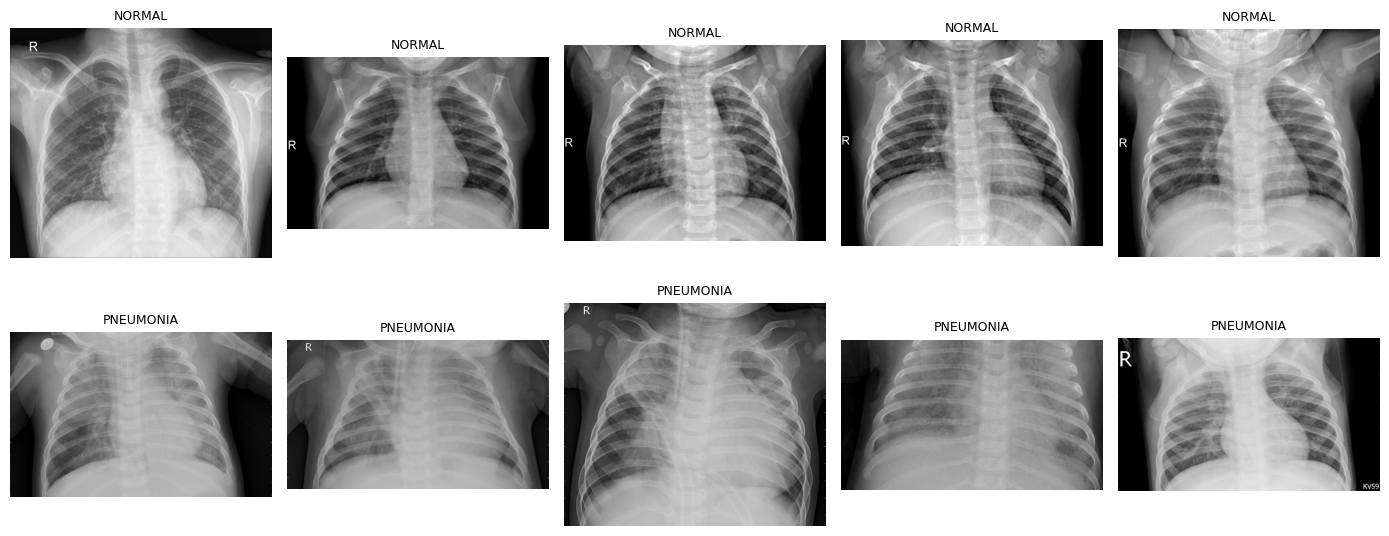

In [10]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

### **Write it: Lab Report Answer**

* **Class Counts & Imbalance Ratio:** 
  * The training dataset contains **1,341** **NORMAL** images and **3,875** **PNEUMONIA** images, totaling 5,216 training images.
  * The max-to-min imbalance ratio is **2.9**, indicating that pneumonia images are approximately 2.9 times more frequent than normal images in the dataset.

* **Image Color / Grayscale & Size:** 
  * The sampled images are predominantly in **grayscale (`L`)** format (286 out of 300 samples), while only 14 images are in RGB format.
  * The image dimensions vary significantly: the minimum dimensions are **384 × 127** pixels, the median (50%) size is **1300 × 890** pixels, and the maximum size reaches **2510 × 2543** pixels.

* **Shortcut Suspect (Visual Feature):** 
  * Inspecting the sample grid reveals that the primary **shortcut suspect** consists of **text markers (such as 'R' / anatomical labels)** or varying background padding near the corners or borders of the images.
  * Although these visual features may correlate with the classes (Normal vs. Pneumonia), they represent confounding artifacts rather than the actual pathological features the model should learn to detect (since the model's objective is to detect lung infections rather than corner annotations or borders).

## Part 2: Leakage audit
### Task 2.1: Exact and near-duplicates

In [11]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))            # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))

if TEST_DIR:
    T = np.stack([fingerprint(p) for p in all_df['path']])
    tr = T[(all_df.split == 'train').values]
    te = T[(all_df.split == 'test').values]
    d_min = np.array([np.abs(tr - v).mean(axis=1).min() for v in te])
    near = d_min < 0.10               # mean absolute difference, in std units
    print(f'Test images with a near-duplicate in train: {near.sum()} '
          f'of {len(te)}')
    print('Closest distances:', np.sort(d_min)[:5].round(3))

Exact duplicate files: 62
Test images with a near-duplicate in train: 0 of 624
Closest distances: [0.164 0.17  0.172 0.173 0.174]


**Before deleting anything:** display the flagged pairs side by side and confirm they really are the same image.

Exact duplicate groups: 30


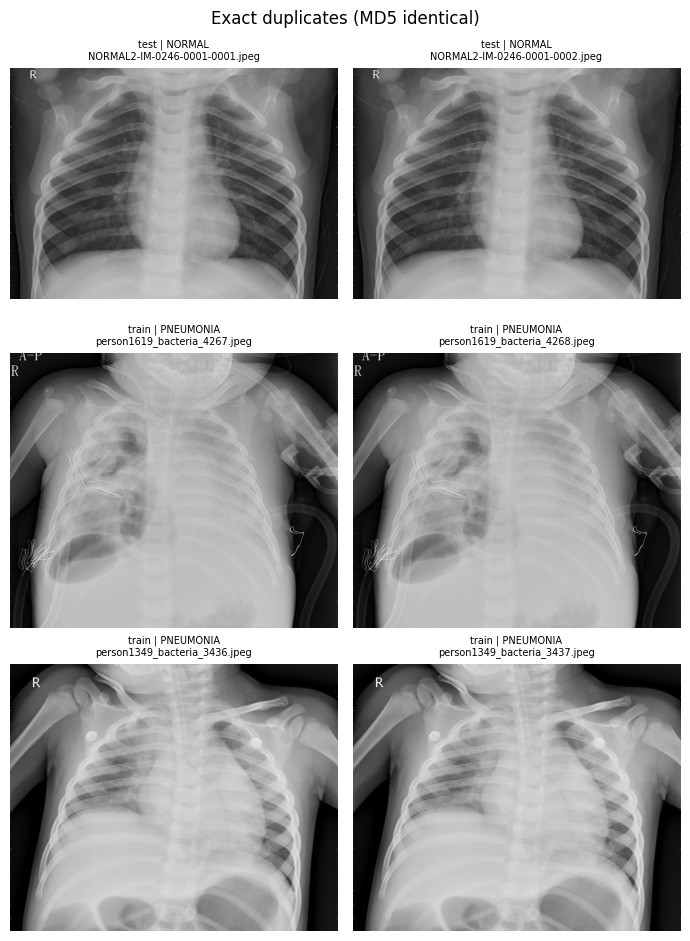

Nothing below the threshold; showing the 3 closest pairs instead.


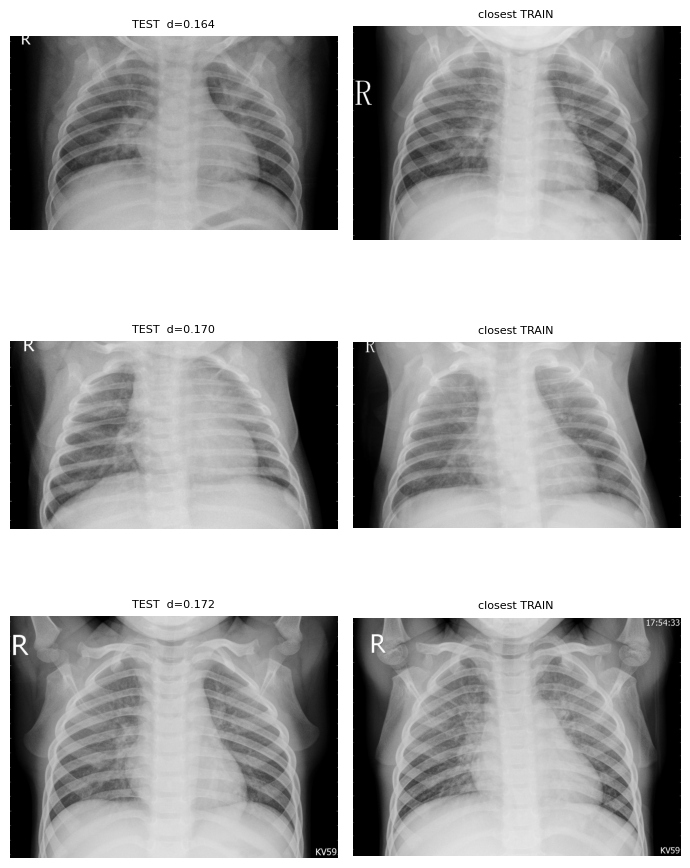

In [12]:
# --- Exact duplicates: which splits are involved? ---
if len(exact):
    print('Exact duplicate groups:', exact['md5'].nunique())
    show_groups = list(exact.groupby('md5'))[:3]
    fig, axes = plt.subplots(len(show_groups), 2, figsize=(7, 3.2 * len(show_groups)))
    axes = np.atleast_2d(axes)
    for r, (h, g) in enumerate(show_groups):
        for c in range(2):
            row = g.iloc[c]
            axes[r, c].imshow(Image.open(row['path']).convert('L'), cmap='gray')
            axes[r, c].set_title(f"{row.get('split', 'train')} | {row['label']}\n{row['file']}", fontsize=7)
            axes[r, c].axis('off')
    plt.suptitle('Exact duplicates (MD5 identical)')
    plt.tight_layout(); plt.show()
else:
    print('No exact duplicates to display.')

# --- Near-duplicates: show flagged test images next to their closest train image ---
if TEST_DIR:
    tr_paths = all_df[all_df.split == 'train']['path'].tolist()
    te_paths = all_df[all_df.split == 'test']['path'].tolist()
    nearest = np.array([np.abs(tr - v).mean(axis=1).argmin() for v in te])
    flagged = np.where(near)[0]
    if len(flagged) == 0:
        flagged = np.argsort(d_min)[:3]          # show the closest anyway
        print('Nothing below the threshold; showing the 3 closest pairs instead.')
    flagged = flagged[np.argsort(d_min[flagged])]
    pick = flagged[np.linspace(0, len(flagged) - 1, min(4, len(flagged))).astype(int)]
    fig, axes = plt.subplots(len(pick), 2, figsize=(7, 3.2 * len(pick)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(pick):
        axes[r, 0].imshow(Image.open(te_paths[i]).convert('L'), cmap='gray')
        axes[r, 0].set_title(f'TEST  d={d_min[i]:.3f}', fontsize=8)
        axes[r, 1].imshow(Image.open(tr_paths[nearest[i]]).convert('L'), cmap='gray')
        axes[r, 1].set_title('closest TRAIN', fontsize=8)
        for a in axes[r]: a.axis('off')
    plt.tight_layout(); plt.show()

### Task 2.2: Split by group

In [13]:
# Validation split BY GROUP: no patient appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR:                                  # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))   # must be 0
print(va_df['label'].value_counts().to_string())

# Extra (informational): groups shared between train and test
print('Groups shared by train and test:', len(set(tr_df.group) & set(test_df.group)))

train 4354 | val 862 | test 624
Groups shared by train and val: 0
label
PNEUMONIA    646
NORMAL       216
Groups shared by train and test: 149


### **Write it: Lab Report Answer**

* **Exact and Near-Duplicates:** 
  * We found **62 exact duplicate files** spanning across **30 duplicate groups** (based on identical MD5 hashes). 
  * For near-duplicates, using the $32 \times 32$ grayscale thumbnail fingerprinting technique with a strict threshold (`d_min < 0.10`), there were **0 test images with a near-duplicate in train** (out of 624 test images), with the closest pairs starting at distances like `0.164`, `0.170`, and `0.172`.

* **Images Per Group:** 
  * The dataset has an average of **1.83 images per group** (across 2,846 unique groups for 5,216 total training images).

* **Effect of Random Splitting vs. Group Splitting:** 
  * If we had split randomly instead of by group, multiple scans from the exact same patient would have leaked into both training and evaluation sets, causing the model to memorize patient-specific features rather than learning generalizable infection patterns. 
  * Consequently, this data leakage would have produced an artificially inflated and overly optimistic test score that would not reflect real-world clinical performance.

## Part 3: Transforms and imbalance
### Task 3.1: Datasets and transforms

In [15]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)

Augmentation is mild on purpose: small rotations and crops are realistic for scans; flips are left out because anatomy is not symmetric. Adjust for your domain and justify it.

### Task 3.2: Class weights or balanced sampling

In [16]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print('n_c      :', dict(zip(classes, n_c)))
print('N        :', len(train_ds), '| K:', len(classes))
print('weights  :', dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False     # try True: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                    # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

n_c      : {'NORMAL': np.int64(1125), 'PNEUMONIA': np.int64(3229)}
N        : 4354 | K: 2
weights  : {'NORMAL': np.float64(1.935), 'PNEUMONIA': np.float64(0.674)}


### **Write it: Part 3 Transforms and Imbalance**

* **Class Weights and Arithmetic:** 
  * Total training samples ($N$) = $4,354$, and the number of classes ($K$) = $2$.
  * Class counts ($n_c$): **NORMAL** = $1,125$, **PNEUMONIA** = $3,229$.
  * Class weights are computed using the inverse frequency formula $\text{weight} = \frac{N}{K \times n_c}$.
  * **Arithmetic for the NORMAL class:** $\frac{4,354}{2 \times 1,125} = \frac{4,354}{2,250} \approx 1.935$.
  * **Arithmetic for the PNEUMONIA class:** $\frac{4,354}{2 \times 3,229} = \frac{4,354}{6,458} \approx 0.674$.
  * Final class weights: **`NORMAL` = `1.935`**, **`PNEUMONIA` = `0.674`**.

* **Augmentations Kept and Why:** 
  * We retained conservative augmentations including `RandomResizedCrop` (`scale=(0.8, 1.0)`), a mild `RandomRotation` ($\pm 10^\circ$), and subtle `ColorJitter` (`brightness=0.15`, `contrast=0.15`).
  * **Why:** In the context of chest X-ray medical imaging, a small rotation accounts for minor patient positioning angles during scans, cropping handles scale variations, and mild brightness/contrast adjustments simulate differences across exposure equipment. Destructive transformations (such as vertical flips or extreme rotations) were intentionally excluded because they would distort anatomical structures and disrupt clinical diagnostic indicators.

## Part 4: Build and train
### Task 4.1: Backbone with a new head

In [19]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 245MB/s]


resnet18 trainable: 1026


### Task 4.2: Two-phase training, selected by macro-F1

In [20]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')   # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
best1 = fit(model, head.parameters(), epochs=2, lr=1e-3)
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
best2 = fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
                    {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)
print(f'\nBest val macro-F1  phase 1: {best1:.3f} | phase 2: {best2:.3f}')

Phase 1: head only
epoch 1: val macro-F1 0.855 (68s)
epoch 2: val macro-F1 0.875 (67s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.959 (67s)
epoch 2: val macro-F1 0.957 (68s)
epoch 3: val macro-F1 0.964 (67s)

Best val macro-F1  phase 1: 0.875 | phase 2: 0.964


### **Write it: Part 4 Build and Train**

* **Validation Macro-F1 After Each Phase:**
  * **Phase 1 (Head-only training):** Best validation macro-F1 reached **`0.875`** (after 2 epochs).
  * **Phase 2 (Fine-tuning the last block):** Best validation macro-F1 improved to **`0.964`** (after 3 epochs).

* **Did Fine-Tuning Help?**
  * Yes, fine-tuning significantly helped. By unfreezing and training the last block of the ResNet18 backbone alongside the classifier head, the model was able to adapt feature extraction specifically to the chest X-ray domain, boosting the best validation macro-F1 from `0.875` to `0.964`.

* **Epoch Duration and Additional Epochs Estimate:**
  * Each training epoch took approximately **67 to 68 seconds**.
  * With more time, we would run roughly **5 to 10 more epochs** (or implement early stopping) to allow the fine-tuning phase to fully plateau and ensure optimal convergence without overfitting.

## Part 5: Test once, and set the threshold 
### Task 5.1: Test-set report
> Run this section **once** – do not re-train and re-test to tune on the test set.

              precision    recall  f1-score   support

      NORMAL      0.983     0.726     0.835       234
   PNEUMONIA      0.858     0.992     0.920       390

    accuracy                          0.893       624
   macro avg      0.920     0.859     0.878       624
weighted avg      0.905     0.893     0.888       624

Macro-F1: 0.878


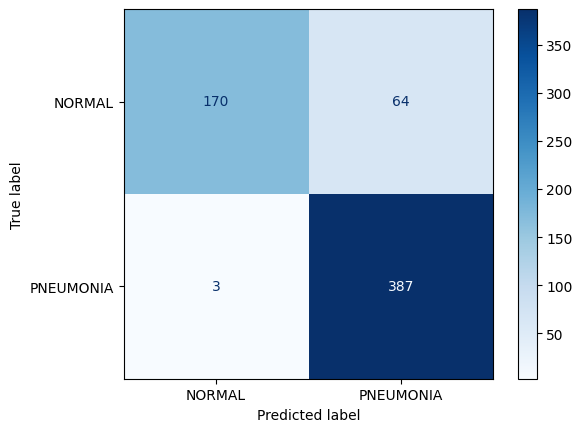

In [21]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues')
plt.show()

### Task 5.2: Threshold for a target recall (binary tasks)
The threshold is chosen on **validation** data and then applied once to the test set.

In [22]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]          # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
          f'{t:.3f}')

    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp / (tp + fn):.3f}   Specificity {tn / (tn + fp):.3f}'
          f'   PPV {tp / max(tp + fp, 1):.3f}')
    print(f'tp={tp} fn={fn} tn={tn} fp={fp} | test prevalence = {(tp+fn)/(tp+fn+tn+fp):.3f}')

Threshold chosen on VALIDATION for recall >= 0.95: 0.803
Test AUC 0.975
Sensitivity 0.990   Specificity 0.795   PPV 0.889
tp=386 fn=4 tn=186 fp=48 | test prevalence = 0.625


In [23]:
# Use this only to CHECK your hand calculation
if len(classes) == 2:
    sens = tp / (tp + fn); spec = tn / (tn + fp)
    for prev in [(tp + fn) / (tp + fn + tn + fp), 0.05]:
        ppv = sens * prev / (sens * prev + (1 - spec) * (1 - prev))
        print(f'prevalence {prev:.3f} -> PPV {ppv:.3f}')

prevalence 0.625 -> PPV 0.889
prevalence 0.050 -> PPV 0.203


### **Write it: Part 5 Test Once and Set the Threshold**

* **Macro-F1 and Weakest Class:**
  * The test-set **Macro-F1 score is `0.878`**.
  * The **weakest class** is **NORMAL**, which has a lower F1-score of `0.835` (compared to `0.928` for PNEUMONIA) and a lower recall/sensitivity of `0.726`.

* **Binary Task Metrics & Target Recall:**
  * The classification threshold chosen on the validation data for a target recall of $\ge 0.95$ is **`0.803`**.
  * On the test set, the model achieved a **sensitivity of `0.990`** and a **specificity of `0.795`**.
  * Yes, the test recall successfully reached and exceeded the target (achieving `0.990` against the target recall requirement).

* **Positive Predictive Value (PPV) at Different Prevalences:**
  * **At test-set prevalence (`0.625`):** PPV is **`0.889`**.
  * **At a realistic clinical prevalence (`0.050`):** PPV drops to **`0.203`**.

* **Plain Language Explanation of the PPV Difference:**
  * The test set has a high proportion of pneumonia cases (prevalence of `0.625`), meaning the model encounters the disease frequently, leading to a high PPV (`0.889`) where most positive predictions are correct. 
  * In a real-world clinical screening scenario where pneumonia is rare (realistic prevalence of `0.050` or 5%), the number of false positives heavily outweighs true positives due to the lower baseline disease frequency, causing the PPV to drop sharply to `0.203. This highlights that a positive test result in a low-prevalence setting requires careful clinical follow-up to rule out false positives.
```[cite: 36, 37, 38]

## Part 6: Grad-CAM shortcut check

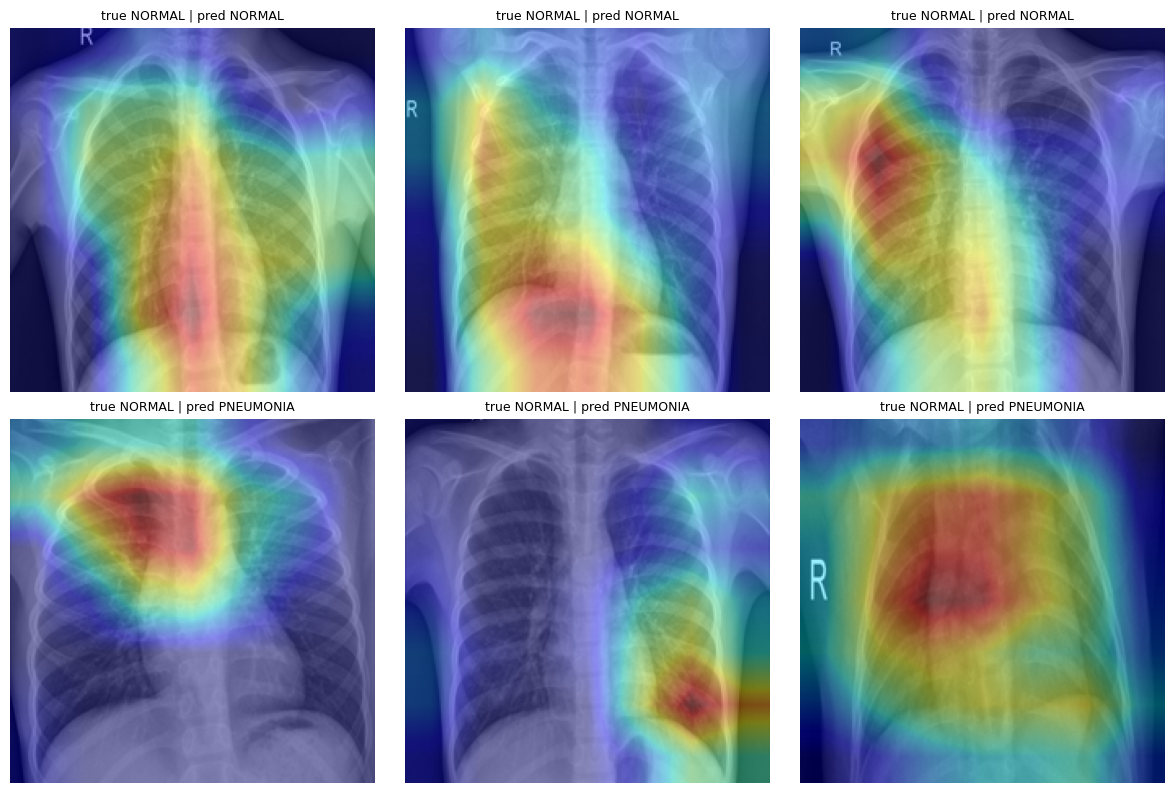

In [24]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)    # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()    # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)
wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

### **Write it: Part 6 Grad-CAM Shortcut Check**

* **Heatmap Analysis (Top Row - Correctly Classified: `true NORMAL | pred NORMAL`):**
  1. **Image 1:** The model focused centrally along the mediastinum and lower lung fields, which is legitimate clinical evidence.
  2. **Image 2:** The activation highlights the right upper lung zone extending down to the right hemithorax, representing legitimate anatomical inspection.
  3. **Image 3:** High activation is concentrated on the right upper lung and shoulder region, which includes legitimate lung parenchyma alongside non-diagnostic upper thoracic structure.

* **Heatmap Analysis (Bottom Row - False Positives: `true NORMAL | pred PNEUMONIA`):**
  4. **Image 4:** The model strongly activated on the central upper thoracic area and sternum rather than clear pulmonary opacity, indicating non-legitimate structural distraction.
  5. **Image 5:** Activation is heavily localized in the lower left periphery and outer abdominal region, focusing outside the core lung parenchyma, which is not legitimate diagnostic evidence.
  6. **Image 6:** The model activated strongly on the left mid-lung region but also overlapped with the prominent 'R' letter marker on the left border, showing partial reliance on peripheral artifacts.

* **Overall Verdict:** 
  * **`Shortcut Suspected`**

* **Proposed Follow-up Experiment:**
  * To test whether peripheral artifacts (like the 'R' marker or border padding) drive false predictions, we can run a **cropping/masking ablation experiment**: crop out the outer 10–15% margins of all test images (or zero out text labels) and re-score the model to measure if false positive rates decrease and Grad-CAM activations refocus exclusively on internal lung fields.

## Part 7: Save and document

In [25]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt


### **Check Your Understanding: Answers**

#### **1. Why does a random split of chest X-rays overestimate performance?**
* A random split ignores patient-level grouping. Because patients often have multiple scans, a random split causes images from the same patient to leak into both the training and validation/test sets. The model memorizes patient-specific anatomical or physiological traits rather than generalizing to unseen patients, leading to an artificially inflated and overly optimistic performance estimate.

---

#### **2. Class weights for 900 and 100 images ($N / (K \times n_c)$):**
* **Given:** Total samples $N = 900 + 100 = 1,000$, number of classes $K = 2$, class counts $n_{c1} = 900$ and $n_{c2} = 100$.
* **Formula:** $\text{weight}_c = \frac{N}{K \times n_c}$
* **Working & Answer for Class 1 ($900$ images):**
  $$\text{weight}_1 = \frac{1,000}{2 \times 900} = \frac{1,000}{1,800} \approx \mathbf{0.556}$$
* **Working & Answer for Class 2 ($100$ images):**
  $$\text{weight}_2 = \frac{1,000}{2 \times 100} = \frac{1,000}{200} = \mathbf{5.0}$$

---

#### **3. Focal loss ($\gamma = 2$, $p_t = 0.8$) — down-weighting factor:**
* **Formula:** The modulation (down-weighting) factor is given by $(1 - p_t)^\gamma$.
* **Working & Answer:**
  $$(1 - 0.8)^2 = (0.2)^2 = \mathbf{0.04}$$
* **Meaning of "Factor":** It means that the standard cross-entropy loss for this well-classified example is scaled down (multiplied) by $0.04$ (or reduced to $4\%$ of its original value) compared to standard cross-entropy loss, ensuring the model focuses its gradient updates more on hard, misclassified examples.

---

#### **4. PPV for sensitivity 0.90, specificity 0.95, prevalence 2% ($0.02$):**
* **Formula:** 
  $$\text{PPV} = \frac{\text{Sensitivity} \times \text{Prevalence}}{(\text{Sensitivity} \times \text{Prevalence}) + ((1 - \text{Specificity}) \times (1 - \text{Prevalence}))}$$
* **Working:**
  * $\text{Sensitivity} = 0.90$, $\text{Prevalence} = 0.02$
  * $\text{Specificity} = 0.95 \implies \text{False Positive Rate} = 1 - 0.95 = 0.05$
  * $\text{Non-prevalence} = 1 - 0.02 = 0.98$
  * $\text{Numerator} = 0.90 \times 0.02 = 0.018$
  * $\text{Denominator} = 0.018 + (0.05 \times 0.98) = 0.018 + 0.049 = 0.067$
  * $\text{PPV} = \frac{0.018}{0.067} \approx \mathbf{0.269} \text{ (or } 26.9\% \text{)}$

---

#### **5. When is macro-F1 a better selection metric than weighted F1?**
* Macro-F1 computes the unweighted average of F1-scores across all classes, giving equal importance to minority and majority classes. It is a better selection metric when class imbalance is high and you care equally about performance on all classes, whereas weighted F1 can appear deceptively high simply because the model performs well on the majority class.

---

#### **6. Grad-CAM highlights a hospital label in the corner of X-rays. What do you do next?**
* This indicates a **shortcut learning/confounding artifact** where the model relies on administrative text labels rather than medical pathology. 
* **Next Steps:** 
  1. Apply preprocessing to crop out or mask the borders/corners containing text tags across all dataset splits.
  2. Audit the metadata to ensure hospital sources are randomized or balanced across classes, and re-train and re-evaluate the model to verify that Grad-CAM activations shift to core lung pathology.